<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/fabiobento/lab-cont-2026-2-privado/blob/main/modulo2_plano_s/labs/gabarito_lab09_pid_e_atraso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

# Gabarito — Lab 09: PID e Atraso de Transporte

**Módulo 02 · Semana 9 · Laboratório de Controle Automático (Ifes Guarapari)**

> **Documento do professor.** Reproduz o `lab09_pid_e_atraso.ipynb` do aluno com comentários teóricos
> estendidos, as equações em LaTeX e — ao final — a resolução completa dos três itens de "Sua vez"
> (entregue no relatório).

Neste laboratório vamos:
1. Projetar um **PID completo** e ajustar o zero do PI;
2. Usar `ct.pade` para modelar o **atraso de transporte** e reconstruir a fronteira $k = a + 2/\tau$;
3. Verificar que a **posição do atraso na malha** muda os tempos, mas não o overshoot;
4. Refazer o **projeto de avanço compensando o atraso** ($M_p = 14{,}3\%$, $t_r = 0{,}5$ s).

**Teoria de apoio:** `teoria_modulo2.md`, §2.5 (receita de bolo, PID, atraso de transporte). Exercícios de referência:
`exercicios_resolvidos_modulo2.md`, Exercícios 2.5.2 e 2.5.3.

In [1]:
# %% IMPORTS (rode esta célula primeiro)
!pip install --quiet control==0.10.2
import control as ct
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, optimize
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True

def step(G, t):
    t, y = ct.step_response(G, t)
    return np.asarray(t), np.asarray(y)

def medir(T, t=None):
    if t is None: t = np.linspace(0, 50, 50000)
    t, y = step(T, t)
    yss = y[-1]
    Mp = 100*(y.max()-yss)/yss; tp = t[np.argmax(y)]
    tr = t[np.argmax(y >= yss)]
    fora = np.where(np.abs(y-yss) > 0.05*abs(yss))[0]
    ts = t[fora[-1]] if len(fora) else 0.0
    return dict(Mp=Mp, tp=tp, tr=tr, ts=ts, yss=yss)

print('python-control', ct.__version__)

python-control 0.10.2


## Parte 1 — O PID completo (Exercício 2.5.2)

$G(s) = \dfrac{2}{(s+2)(s+5)}$, requisitos $M_p = 16{,}3\%$, $t_p = 400$ ms, $e_{ss}(\text{degrau}) = 0$.
Do quadro: $\square_d = -4{,}6+7{,}9j$, avanço $15{,}3°$, zero do PD em $-33{,}4$, $k = 1{,}1$.
Só falta o zero do PI — testamos as três posições da teoria:

In [2]:
# Conferindo as contas "do quadro" (receita de bolo, passos 1-7)
sd = -4.6 + 7.9j
G = ct.tf([2], [1, 7, 10])
angG = np.degrees(np.angle(2/((sd+2)*(sd+5)))) - 360       # ∠G(□d), levado para (−360°, 0°]
avanco = -angG - 180
a_PD = -sd.real + sd.imag/np.tan(np.radians(avanco))        # tg(avanço) = ωd/(a − σ)
print(f'∠G(□d) = {angG:.2f}°  → avanço necessário = {avanco:.2f}°  → zero do PD em −{a_PD:.1f}')
for z in [0.46, 1, 2]:
    k = abs(sd)*abs(sd+2)*abs(sd+5)/(2*abs(sd+33.4)*abs(sd+z))      # não esquecer do A = 2
    print(f'  zero do PI em −{z}: k = {k:.3f}')

∠G(□d) = -195.32°  → avanço necessário = 15.32°  → zero do PD em −33.4
  zero do PI em −0.46: k = 1.129
  zero do PI em −1: k = 1.160
  zero do PI em −2: k = 1.211


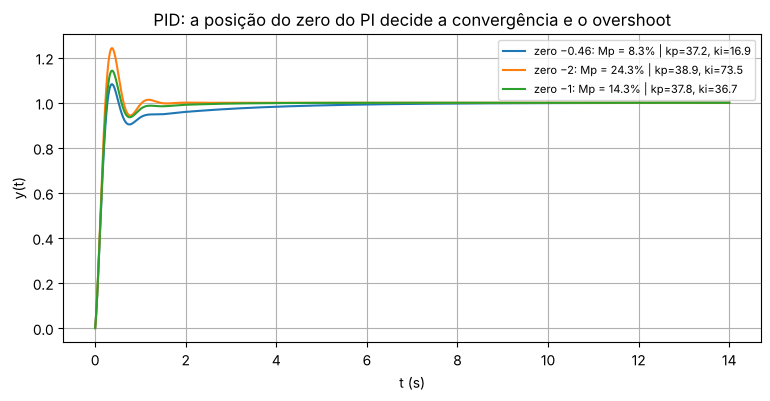

In [3]:
G = ct.tf([2], [1, 7, 10])
t = np.linspace(0, 14, 14000)
for zpi in [0.46, 2, 1]:
    Cpid = 1.1*ct.tf([1, 33.4], [1]) * ct.tf([1, zpi], [1, 0])
    T = ct.feedback(Cpid*G, 1)
    m = medir(T, t)
    # kp, ki, kd: expandir (s+33,4)(s+zpi) = s² + (33,4+zpi)s + 33,4·zpi → C = kd·s + kp + ki/s
    kp = 1.1*(33.4+zpi); ki = 1.1*33.4*zpi; kd = 1.1
    plt.plot(*step(T, t), label=f'zero −{zpi}: Mp = {m["Mp"]:.1f}% | kp={kp:.1f}, ki={ki:.1f}')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend(fontsize=8)
plt.title('PID: a posição do zero do PI decide a convergência e o overshoot');

**✏️ Responda:** por que o zero muito perto da origem ($-0{,}46$) deixa a convergência lenta?
E por que $-2$ gera overshoot grande? (Lembre do efeito do zero, §2.1.9, e do quase-cancelamento.)

In [4]:
# Polos de MF, resíduos do degrau e fase "roubada" pelo fator do PI, (s+z)/s, em □d
for z in [0.46, 1, 2]:
    T = ct.feedback(1.1*ct.tf([1, 33.4], [1])*ct.tf([1, z], [1, 0])*G, 1)
    m = medir(T, t)
    r, p, _ = signal.residue(T.num[0][0], np.polymul(T.den[0][0], [1, 0]))
    par = [q for q in ct.poles(T) if q.imag > 1e-6][0]
    lento = [(q, rr) for q, rr in zip(p, r) if abs(q.imag) < 1e-6 and abs(q) > 1e-9][0]
    fase_PI = np.degrees(np.angle(sd + z) - np.angle(sd))
    print(f'zero −{z:<4}: fase do PI em □d = {fase_PI:6.2f}° | par MF {par:.3f} (ζ = {-par.real/abs(par):.3f}) '
          f'| polo real {lento[0].real:6.3f}, resíduo {lento[1].real:+.4f} | Mp = {m["Mp"]:.1f}%, ts = {m["ts"]:.2f} s')

zero −0.46: fase do PI em □d =  -2.55° | par MF -4.391+7.845j (ζ = 0.488) | polo real -0.418, resíduo -0.0937 | Mp = 8.3%, ts = 1.53 s
zero −1   : fase do PI em □d =  -5.71° | par MF -4.128+7.801j (ζ = 0.468) | polo real -0.943, resíduo -0.0604 | Mp = 14.3%, ts = 0.88 s


zero −2   : fase do PI em □d = -11.99° | par MF -3.600+7.779j (ζ = 0.420) | polo real -2.000, resíduo +0.0000 | Mp = 24.3%, ts = 0.84 s


**Leitura do resultado (e resposta ao ✏️ Responda).** É o **Exercício 2.5.2**. Confirmamos as contas do quadro
($\angle G(\square_d)=-195{,}3°$, avanço $15{,}3°$, $a=33{,}4$). O $k$ de cada caso sai em $1{,}13$, $1{,}16$ e $1{,}21$ (para os zeros
$-0{,}46,\,-1,\,-2$) — o "$k=1{,}1$" do quadro é o arredondamento do primeiro caso, e a diferença é desprezível na simulação.

| Zero do PI | $k_p$ | $k_i$ | Fase do PI em $\square_d$ | Polos de MF | $M_p$ | $t_s$ (5%) |
|---|---|---|---|---|---|---|
| $-0{,}46$ | $37{,}25$ | $16{,}9$ | $-2{,}6°$ | $-4{,}39\pm7{,}85j$; $-0{,}418$ | $8{,}3\%$ | $1{,}53$ s |
| $-1$ | $37{,}8$ | $36{,}7$ | $-5{,}7°$ | $-4{,}13\pm7{,}80j$; $-0{,}943$ | $14{,}3\%$ | $0{,}88$ s |
| $-2$ | $38{,}9$ | $73{,}5$ | $-12{,}0°$ | $-3{,}60\pm7{,}78j$; $-2{,}000$ | $24{,}3\%$ | $0{,}84$ s |

- **Zero em $-0{,}46$ (lento):** o integrador fica quase "puro": o 3º polo de MF cai em $-0{,}418$, a apenas
  $0{,}04$ do zero ($-0{,}46$) — **quase-cancelamento**, só que imperfeito: o resíduo desse modo é $-0{,}094$ (≈ $9\%$ do
  valor final), e ele só decai com constante de tempo $1/0{,}418\approx2{,}4$ s. O par complexo fica no lugar projetado
  (e com *menos* overshoot, $8{,}3\%<16{,}3\%$), mas a saída termina de chegar a $1$ devagar — por isso $t_s$ é quase o
  dobro do caso $-1$.
- **Zero em $-2$ (rápido demais):** o zero do PI **cancela exatamente o polo $-2$ da planta** — o polo real de MF vai
  para $-2$ com resíduo **zero** (não há cauda lenta alguma). Mas aqui o problema é outro: um zero longe da origem
  rouba **muita fase** ($-12{,}0°$, contra $-2{,}6°$ do primeiro caso). O par dominante se afasta do desejado
  ($\zeta$ cai de $0{,}49$ para $0{,}42$) e o overshoot sobe para $24\%$.
- **Zero em $-1$:** meio-termo — fase de $-5{,}7°$, $M_p=14{,}3\%$ (dentro da especificação, $\le16{,}3\%$), cauda curta
  (polo em $-0{,}943$, resíduo $-0{,}06$): **resposta satisfatória** ✓.

Moral (a mesma da Parte 3 do Lab 08): o zero do PI é *ajustado por simulação* — perto da origem custa tempo de
convergência; longe, custa fase (overshoot).

## Parte 2 — Padé e a fronteira de estabilidade $k = a + 2/\tau$

Para $G(s) = \dfrac{1}{s+a}$, o sistema sem atraso é estável para todo $k > 0$.
Com atraso $\tau$ (Padé de 1ª ordem): **instável se $k > a + 2/\tau$** (§2.5.5).
Vamos reconstruir essa fronteira numericamente, varrendo $k$ para vários $\tau$:

τ = 0.05: k crítico numérico = 44.0 | teoria a+2/τ = 44.0


τ = 0.1: k crítico numérico = 24.0 | teoria a+2/τ = 24.0


τ = 0.2: k crítico numérico = 14.0 | teoria a+2/τ = 14.0
τ = 0.3: k crítico numérico = 10.8 | teoria a+2/τ = 10.7


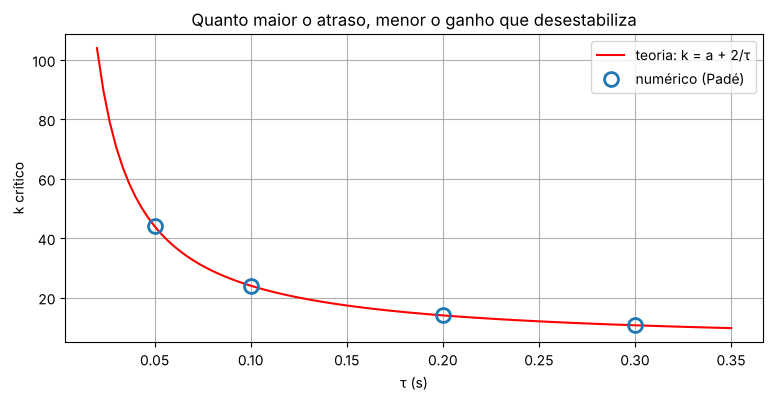

In [5]:
taus = [0.05, 0.1, 0.2, 0.3]
kmax_num = []
for tau in taus:
    n, d = ct.pade(tau, 1)
    P = ct.tf(n, d)
    Ga = ct.tf([1], [1, 4])*P        # G = 1/(s+4) com atraso
    kmax = None
    for k in np.linspace(1, 60, 600):
        if any(p.real >= 0 for p in ct.poles(ct.feedback(k*Ga, 1))):
            kmax = k; break
    kmax_num.append(kmax)
    print(f'τ = {tau}: k crítico numérico = {kmax:.1f} | teoria a+2/τ = {4 + 2/tau:.1f}')

tt = np.linspace(0.02, 0.35, 100)
plt.plot(tt, 4 + 2/tt, 'r-', label='teoria: k = a + 2/τ')
plt.plot(taus, kmax_num, 'o', ms=10, mfc='none', mew=2, label='numérico (Padé)')
plt.xlabel('τ (s)'); plt.ylabel('k crítico'); plt.legend()
plt.title('Quanto maior o atraso, menor o ganho que desestabiliza');

In [6]:
# Por que a fronteira é a + 2/τ? Equação característica (Padé 1ª ordem): (s+a)(s+2/τ) + k(−s+2/τ) = 0
#   Δ(s) = s² + (a + 2/τ − k)s + 2(a+k)/τ     →  Routh de 2ª ordem: todos os coeficientes > 0
a, tau = 4, 0.1
print('coeficientes de Δ(s) (a=4, τ=0,1, k=10):', np.polyadd(np.polymul([1, a], [1, 2/tau]), 10*np.array([-1, 2/tau])))
for k in [23.9, 24.0, 24.1]:
    d = np.polyadd(np.polymul([1, a], [1, 2/tau]), k*np.array([-1, 2/tau]))
    print(f'  k = {k}: coef. de s = {d[1]:+.2f}  polos = {np.round(np.roots(d), 3)}')
# O "k crítico" da varredura é o primeiro k da malha com polo em Re ≥ 0, logo ligeiramente acima da fronteira:
print('passo da varredura =', np.round(np.diff(np.linspace(1, 60, 600))[0], 4))

coeficientes de Δ(s) (a=4, τ=0,1, k=10): [  1.  14. 280.]
  k = 23.9: coef. de s = +0.10  polos = [-0.05+23.622j -0.05-23.622j]
  k = 24.0: coef. de s = +0.00  polos = [-0.+23.664j  0.-23.664j]
  k = 24.1: coef. de s = -0.10  polos = [0.05+23.706j 0.05-23.706j]
passo da varredura = 0.0985


**Leitura do resultado.** A varredura reproduz a fronteira da teoria:

| $\tau$ (s) | $a+2/\tau$ | $k$ crítico (varredura) |
|---|---|---|
| $0{,}05$ | $44{,}0$ | $44{,}0$ |
| $0{,}10$ | $24{,}0$ | $24{,}0$ |
| $0{,}20$ | $14{,}0$ | $14{,}0$ |
| $0{,}30$ | $10{,}67$ | $10{,}8$ (passo $0{,}1$ da varredura) |

A origem da fronteira está na equação característica: com Padé de 1ª ordem,
$$\Delta(s)=(s+a)\Bigl(s+\tfrac2\tau\Bigr)+k\Bigl(-s+\tfrac2\tau\Bigr)=s^2+\Bigl(a+\tfrac2\tau-k\Bigr)s+\tfrac{2(a+k)}{\tau}.$$
Para um polinômio de 2ª ordem basta que **os coeficientes sejam positivos**: o termo independente é sempre positivo ($k>0$)
e o coeficiente de $s$ muda de sinal em $k=a+2/\tau$ — nesse ponto os polos cruzam o eixo imaginário em
$s=\pm j\sqrt{2(a+k)/\tau}$ (para $\tau=0{,}1$: $\pm j\,23{,}7$ rad/s). A varredura mostra isso: em $k=23{,}9$ os polos são
$-0{,}05\pm 23{,}6j$; em $k=24{,}1$, $+0{,}05\pm 23{,}7j$. **Quanto maior o atraso, menor o ganho que desestabiliza.**
(Veja no item 2 de "Sua vez" que essa fronteira é uma propriedade da Padé de 1ª ordem, não do atraso verdadeiro.)

## Parte 3 — A posição do atraso na malha

$G(s) = \dfrac{2}{s(s+4)}$, $\tau = 0{,}1$ s, $k = 10$. O atraso pode estar na **malha direta**,
na **realimentação** ou **dividido** entre os dois. Regra da teoria: **o overshoot é o mesmo;
os tempos mudam.** Confira:

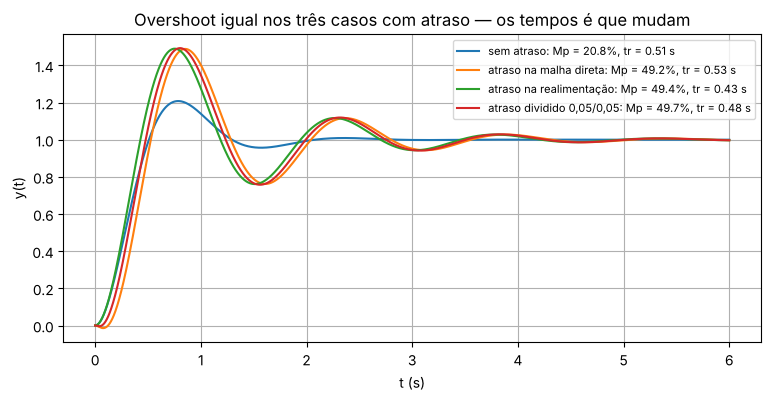

In [7]:
G = ct.tf([2], [1, 4, 0])
n, d = ct.pade(0.1, 1)
P = ct.tf(n, d)
n2, d2 = ct.pade(0.05, 1)
P2 = ct.tf(n2, d2)
k = 10
casos = {
    'sem atraso': ct.feedback(k*G, 1),
    'atraso na malha direta': ct.feedback(k*P*G, 1),
    'atraso na realimentação': ct.feedback(k*G, P),
    'atraso dividido 0,05/0,05': ct.feedback(k*P2*G, P2),
}
t = np.linspace(0, 6, 6000)
for nome, T in casos.items():
    m = medir(T, t)
    plt.plot(*step(T, t), label=f'{nome}: Mp = {m["Mp"]:.1f}%, tr = {m["tr"]:.2f} s')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend(fontsize=8)
plt.title('Overshoot igual nos três casos com atraso — os tempos é que mudam');

**✏️ Responda:** por que o overshoot não depende da posição do atraso, mas o tempo de subida sim?
(Dica: pense em quem é a equação característica em cada caso — e o que o atraso faz com o sinal **medido**.)

In [8]:
# (1) Equação característica: 1 + k·G·P em AMBOS os casos (a ordem dos blocos na malha não importa)
Td = casos['atraso na malha direta']; Tf = casos['atraso na realimentação']
print('polos (direta)      :', np.round(np.sort_complex(ct.poles(Td)), 4))
print('polos (realimentação):', np.round(np.sort_complex(ct.poles(Tf)), 4))

# (2) Relação exata entre as duas respostas: Y_direta(s) = P(s)·Y_realim(s)  (P = o próprio atraso)
dif = ct.minreal(Td - P*Tf, verbose=False)
print('Td − P·Tf =', np.round(dif.num[0][0], 12), '(zero: igualdade exata)')

# (3) Atraso "quase exato" (Padé de 6ª ordem) para conferir que o resultado não é artefato da Padé de 1ª
P6 = ct.tf(*ct.pade(0.1, 6)); P6b = ct.tf(*ct.pade(0.05, 6))
exatos = {'direta': ct.feedback(k*P6*G, 1), 'realimentação': ct.feedback(k*G, P6), 'dividido': ct.feedback(k*P6b*G, P6b)}
print(f'\n{"":16s}{"Padé 1ª ordem":>28s}{"Padé 6ª ordem (≈ exato)":>30s}')
for (nome, T), (_, T6) in zip(list(casos.items())[1:], exatos.items()):
    m, m6 = medir(T, t), medir(T6, t)
    print(f'{nome:26s} Mp = {m["Mp"]:5.2f}%  tr = {m["tr"]:.3f} s     Mp = {m6["Mp"]:5.2f}%  tr = {m6["tr"]:.3f} s')
print(f'\nsem atraso: Mp = {medir(casos["sem atraso"], t)["Mp"]:.2f}%, tr = {medir(casos["sem atraso"], t)["tr"]:.3f} s')

polos (direta)      : [-22.1043+0.j     -0.9479-4.147j  -0.9479+4.147j]
polos (realimentação): [-22.1043+0.j     -0.9479-4.147j  -0.9479+4.147j]
Td − P·Tf = [0.] (zero: igualdade exata)

                               Padé 1ª ordem       Padé 6ª ordem (≈ exato)
atraso na malha direta     Mp = 49.22%  tr = 0.526 s     Mp = 49.82%  tr = 0.528 s


atraso na realimentação    Mp = 49.45%  tr = 0.427 s     Mp = 49.92%  tr = 0.428 s
atraso dividido 0,05/0,05  Mp = 49.74%  tr = 0.478 s     Mp = 49.88%  tr = 0.478 s



sem atraso: Mp = 20.79%, tr = 0.509 s


**Leitura do resultado (e resposta ao ✏️ Responda).** É a "Exercício de simulação" da §2.5.5. Sem atraso, $k=10$ dá $M_p=20{,}8\%$;
com atraso (qualquer posição) o overshoot salta para **cerca de $49\%$**:

| Posição do atraso | $M_p$ | $t_r$ |
|---|---|---|
| sem atraso | $20{,}8\%$ | $0{,}509$ s |
| malha direta | $49{,}2\%$ | $0{,}526$ s |
| realimentação | $49{,}4\%$ | $0{,}427$ s |
| dividido $0{,}05/0{,}05$ | $49{,}7\%$ | $0{,}478$ s |

(com o atraso "quase exato", Padé de 6ª ordem: $49{,}8\%$, $49{,}9\%$, $49{,}9\%$ e os mesmos tempos — a pequena diferença entre as
três posições é só efeito da aproximação.)

**Por quê?** (i) **Mesma equação característica.** Em toda posição a malha tem $L(s)=kG(s)P(s)$ e
$\Delta(s)=1+L(s)$; os polos de MF são os mesmos ($-22{,}10$ e $-0{,}948\pm4{,}147j$), e o overshoot é fixado pelos polos
dominantes. (ii) **As respostas diferem apenas por um deslocamento no tempo.** De
$T_{dir}=\dfrac{kGP}{1+kGP}$ e $T_{real}=\dfrac{kG}{1+kGP}$ segue **$T_{dir}(s)=P(s)\,T_{real}(s)$** — a verificação numérica deu
diferença nula. Ou seja: a saída com o atraso na malha direta é a da realimentação **atrasada de $\tau$**: mesma forma
(mesmo $M_p$), mas $t_r$ deslocado de $0{,}1$ s ($0{,}427\to0{,}526$; no dividido, a metade, $0{,}05$ s: $0{,}478$).
**O sinal medido:** com o atraso na realimentação, o controlador vê o passado; quem **demora a perceber** é a malha, não a
saída — ela já está subindo "ao vivo", e o $t_r$ medido na saída é o menor. Com o atraso na entrada, a planta só
recebe a ação $\tau$ depois e a saída só começa a se mexer depois. Por isso, no projeto (Parte 4), **toda posição do
atraso exige compensar a mesma fase** (para o overshoot) e só o atraso da malha direta entra na conta do tempo de subida.

## Parte 4 — Projeto de avanço compensando o atraso (Exercício 2.5.3)

Requisitos $t_r = 0{,}5$ s e $M_p = 15\%$ com $\tau = 0{,}1$ s.
Do quadro: $\square_d = -2{,}6+4{,}2j$; avanço sem atraso $13{,}4°$; fase do atraso $-24{,}1°$;
**total $37{,}5°$ (dentro dos 40°)**; cancelamento do $-4$: $b = 8{,}8$, $k = 14{,}26$.
Primeiro, o desastre de **ignorar** o atraso no projeto; depois, o projeto correto:

In [9]:
# Conferindo as contas do quadro (G = 2/[s(s+4)], □d = −2,6 + 4,2j)
sd = -2.6 + 4.2j
G = ct.tf([2], [1, 4, 0])
angG = np.degrees(np.angle(2/(sd*(sd+4)))) - 360
lead = -angG - 180
fase_exp = -np.degrees(0.1*sd.imag)                                  # ∠e^{−τ□d} = −τ·ωd
fase_pade = np.degrees(np.angle(-sd+20) - np.angle(sd+20))           # ∠[(−□d+20)/(□d+20)]
print(f'∠G(□d) = {angG:.2f}° → avanço sem atraso = {lead:.2f}°')
print(f'fase do atraso: exponencial = {fase_exp:.2f}° | Padé 1ª ordem = {fase_pade:.2f}°')
total = lead - fase_exp
zero_fase = np.degrees(np.angle(sd + 4))
polo_fase = zero_fase - total
b = -sd.real + sd.imag/np.tan(np.radians(polo_fase))
print(f'avanço total = {total:.2f}° | fase do zero (−4) = {zero_fase:.2f}° | fase do polo = {polo_fase:.2f}° | b = {b:.2f}')
# ganho: cancelando o polo −4, |C·G·atraso(□d)| = 1  →  k = |□d|·|□d+b| / (2·|atraso(□d)|)
k_exp = abs(sd)*abs(sd+8.8)/(2*np.exp(0.1*(-sd.real)))
k_pade = abs(sd)*abs(sd+8.8)/(2*abs((-sd+20)/(sd+20)))
print(f'ganho: módulo da exponencial → k = {k_exp:.2f} | módulo da Padé → k = {k_pade:.2f}')

∠G(□d) = -193.32° → avanço sem atraso = 13.32°
fase do atraso: exponencial = -24.06° | Padé 1ª ordem = -24.10°
avanço total = 37.39° | fase do zero (−4) = 71.57° | fase do polo = 34.18° | b = 8.79
ganho: módulo da exponencial → k = 14.26 | módulo da Padé → k = 14.40


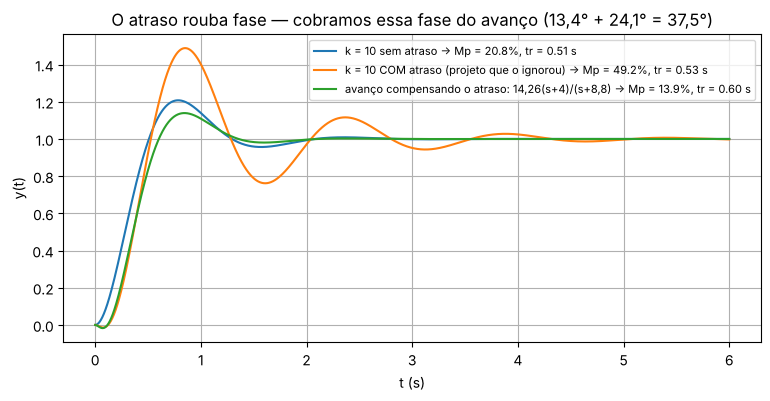

In [10]:
k = 10  # projeto que ignorava o atraso (Mp = 20,8% sem atraso)
T_sematraso = ct.feedback(k*G, 1)
T_ignorado = ct.feedback(k*P*G, 1)
C = 14.26*ct.tf([1, 4], [1, 8.8])
T_proj = ct.feedback(C*P*G, 1)

t = np.linspace(0, 6, 6000)
for nome, T in [('k = 10 sem atraso', T_sematraso),
                ('k = 10 COM atraso (projeto que o ignorou)', T_ignorado),
                ('avanço compensando o atraso: 14,26(s+4)/(s+8,8)', T_proj)]:
    m = medir(T, t)
    plt.plot(*step(T, t), label=f'{nome} → Mp = {m["Mp"]:.1f}%, tr = {m["tr"]:.2f} s')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend(fontsize=8)
plt.title('O atraso rouba fase — cobramos essa fase do avanço (13,4° + 24,1° = 37,5°)');

In [11]:
# O projeto é para o atraso NA REALIMENTAÇÃO (tr = 0,5 s). No código acima o atraso foi colocado na MALHA DIRETA.
t = np.linspace(0, 6, 12000)
P6 = ct.tf(*ct.pade(0.1, 6)); P6b = ct.tf(*ct.pade(0.05, 6)); P2 = ct.tf(*ct.pade(0.05, 1))
linhas = {
  'realimentação (Padé 1)':  ct.feedback(C*G, P),
  'malha direta  (Padé 1)':  ct.feedback(C*P*G, 1),
  'dividido 0,05/0,05 (Padé 1)': ct.feedback(C*P2*G, P2),
  'realimentação (≈ exato, Padé 6)': ct.feedback(C*G, P6),
  'malha direta  (≈ exato, Padé 6)': ct.feedback(C*P6*G, 1),
}
for nome, T in linhas.items():
    m = medir(T, t); print(f'{nome:34s}: Mp = {m["Mp"]:5.2f}%  tr = {m["tr"]:.3f} s  ts = {m["ts"]:.2f} s')
# Se tivéssemos projetado só com os 13,4° (sem compensar o atraso):
bb = 2.6 + 4.2/np.tan(np.radians(zero_fase - lead)); kk = abs(sd)*abs(sd+bb)/2
C2 = kk*ct.tf([1, 4], [1, bb])
m0, m1 = medir(ct.feedback(C2*G, 1), t), medir(ct.feedback(C2*G, P), t)
print(f'\navanço só com 13,4° (b = {bb:.2f}, k = {kk:.2f}): sem atraso Mp = {m0["Mp"]:.1f}% → com atraso Mp = {m1["Mp"]:.1f}%')

realimentação (Padé 1)            : Mp = 14.07%  tr = 0.503 s  ts = 1.07 s
malha direta  (Padé 1)            : Mp = 13.92%  tr = 0.603 s  ts = 1.17 s


dividido 0,05/0,05 (Padé 1)       : Mp = 14.23%  tr = 0.552 s  ts = 1.12 s
realimentação (≈ exato, Padé 6)   : Mp = 14.31%  tr = 0.501 s  ts = 1.07 s
malha direta  (≈ exato, Padé 6)   : Mp = 14.31%  tr = 0.601 s  ts = 1.17 s



avanço só com 13,4° (b = 5.20, k = 12.20): sem atraso Mp = 14.3% → com atraso Mp = 40.8%


**Leitura do resultado.** É o **Exercício 2.5.3**. As contas do quadro se confirmam: $\angle G(\square_d)=-193{,}3°$ (avanço
$13{,}3°$; o quadro arredonda para $13{,}4°$, daí o total $37{,}4°$ contra $37{,}5°$), fase do atraso $-24{,}06°$ (exponencial) $\approx -24{,}10°$ (Padé), $b=8{,}79\approx8{,}8$ e $k=14{,}26$ quando se usa o **módulo da
exponencial** ($|e^{-0{,}1\square_d}|=e^{0{,}26}=1{,}297$). Com o módulo da **Padé** ($1{,}284$) o ganho sai $14{,}40$ — a
afirmação "mesmo resultado" da teoria vale para a fase, mas o módulo difere $\approx1\%$; na prática, irrelevante.

| Caso | $M_p$ | $t_r$ |
|---|---|---|
| $k=10$, sem atraso | $20{,}8\%$ | $0{,}51$ s |
| $k=10$, com atraso (projeto que o ignorou) | $49{,}2\%$ | $0{,}53$ s |
| avanço só com os $13{,}4°$ (ignora o atraso), com atraso | $40{,}8\%$ | $0{,}41$ s |
| **avanço compensando o atraso**, realimentação | **$14{,}1\%$** (Padé 6: $14{,}3\%$) | **$0{,}50$ s** ✓ |
| mesmo avanço, malha direta | $13{,}9\%$ | $0{,}60$ s |
| mesmo avanço, dividido | $14{,}2\%$ | $0{,}55$ s |

**Atenção — discrepância no código do aluno.** A célula do laboratório coloca o atraso na **malha direta**
(`ct.feedback(C*P*G, 1)`), enquanto o projeto (e o texto da teoria) supõem o atraso na **realimentação**. Resultado: o
aluno vê $t_r=0{,}60$ s no gráfico, não $0{,}5$ s — e nada está errado: é exatamente o "$+0{,}1$ s" previsto na §2.5.5
(overshoot igual, tempo deslocado de $\tau$). Para ver o $0{,}5$ s do objetivo, usar `ct.feedback(C*G, P)`.

Ignorar o atraso é caro: o avanço projetado só com $13{,}4°$ (que dá $14{,}3\%$ **sem** atraso) vira $40{,}8\%$ **com** atraso; o projeto
que compensa os $24{,}1°$ restaura os $\approx14\%$. A conta cabe nos $40°$ da regra prática ($37{,}5°$ de avanço total).

---
# Respostas do relatório

## Resposta 1 — PID = PI-Lead (PID "de verdade", $N=100$)

**Dedução.** Com o zero do PI em $-1$: $C(s)=1{,}1\,\dfrac{(s+33{,}4)(s+1)}{s}=k_ds+k_p+\dfrac{k_i}{s}$ com
$k_d=1{,}1$, $k_p=1{,}1\cdot34{,}4=37{,}84$, $k_i=1{,}1\cdot33{,}4=36{,}74$. Na forma implementável o derivador ganha um polo de filtro em $-N$:

$$C_{real}(s)=k_p+\frac{k_i}{s}+k_d\frac{N}{1+N/s}=k_p+\frac{k_i}{s}+\frac{k_dN\,s}{s+N}
=\frac{(k_p+Nk_d)s^2+(Nk_p+k_i)s+Nk_i}{s\,(s+N)}.$$

O denominador é $s(s+N)$ — um **integrador** mais um **polo em $-N$** — e o numerador de 2ª ordem tem duas raízes reais:
$C_{real}=K\dfrac{(s+z_1)}{s}\cdot\dfrac{(s+z_2)}{(s+N)}$ = **(PI) × (avanço com polo em $-N$)**. É isso que significa "PID real = PI-Lead".

kp = 37.84, ki = 36.74, kd = 1.1
C_real = 147.84·(s+1.0003)(s+24.84) / [s(s+100)]   ← PI (zero −1.00) × avanço (zero −24.84, polo −100)


PID ideal             : Mp = 14.26%  tp = 0.373 s  tr = 0.249 s  ts = 0.881 s


PID real, N=100       : Mp = 14.35%  tp = 0.367 s  tr = 0.245 s  ts = 0.870 s


PI × avanço (equiv.)  : Mp = 14.35%  tp = 0.367 s  tr = 0.245 s  ts = 0.870 s
máx |y_ideal − y_real| = 0.0165 | máx |y_real − y_PI×avanço| = 0.0e+00
fase do polo de filtro (−100) em □d: 4.73°
  N =   10: Mp = 20.09%, tr = 0.228 s


  N =   30: Mp = 15.29%, tr = 0.236 s
  N =  100: Mp = 14.35%, tr = 0.245 s


  N = 1000: Mp = 14.26%, tr = 0.249 s


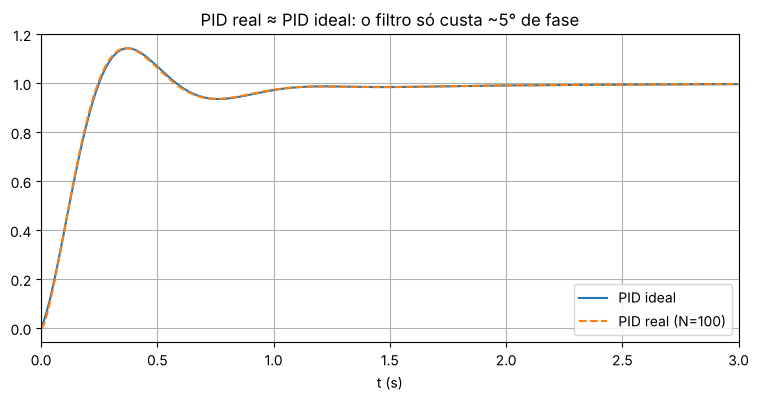

In [12]:
sd = -4.6 + 7.9j
Gp = ct.tf([2], [1, 7, 10]); t = np.linspace(0, 14, 14000)
kd, kp, ki, N = 1.1, 1.1*34.4, 1.1*33.4, 100
print(f'kp = {kp:.2f}, ki = {ki:.2f}, kd = {kd}')

C_ideal = ct.tf([kd, kp, ki], [1, 0])
C_real = ct.minreal(ct.tf([kp], [1]) + ct.tf([ki], [1, 0]) + ct.tf([kd*N, 0], [1, N]), verbose=False)
K = C_real.num[0][0][0]; z1, z2 = np.sort(-np.roots(C_real.num[0][0]))     # zeros do numerador, com sinal trocado
print(f'C_real = {K:.2f}·(s+{z1:.4f})(s+{z2:.2f}) / [s(s+{N})]   ← PI (zero −{z1:.2f}) × avanço (zero −{z2:.2f}, polo −{N})')
C_lead = K*ct.tf([1, z1], [1, 0])*ct.tf([1, z2], [1, N])                       # PI × avanço equivalente
T = {nome: ct.feedback(Cx*Gp, 1) for nome, Cx in [('PID ideal', C_ideal), (f'PID real, N={N}', C_real), ('PI × avanço (equiv.)', C_lead)]}
y = {}
for nome, Tx in T.items():
    m = medir(Tx, t); y[nome] = step(Tx, t)[1]
    print(f'{nome:22s}: Mp = {m["Mp"]:.2f}%  tp = {m["tp"]:.3f} s  tr = {m["tr"]:.3f} s  ts = {m["ts"]:.3f} s')
print(f'máx |y_ideal − y_real| = {np.abs(y["PID ideal"] - y[f"PID real, N={N}"]).max():.4f} | '
      f'máx |y_real − y_PI×avanço| = {np.abs(y[f"PID real, N={N}"] - y["PI × avanço (equiv.)"]).max():.1e}')
print('fase do polo de filtro (−100) em □d:', f'{np.degrees(np.angle(sd+N)):.2f}°')
for Nx in (10, 30, 100, 1000):
    Cx = ct.tf([kp], [1]) + ct.tf([ki], [1, 0]) + ct.tf([kd*Nx, 0], [1, Nx])
    m = medir(ct.feedback(Cx*Gp, 1), t); print(f'  N = {Nx:>4}: Mp = {m["Mp"]:.2f}%, tr = {m["tr"]:.3f} s')
plt.plot(t, y['PID ideal'], label='PID ideal'); plt.plot(t, y[f'PID real, N={N}'], '--', label=f'PID real (N={N})')
plt.xlim(0, 3); plt.legend(); plt.xlabel('t (s)'); plt.title('PID real ≈ PID ideal: o filtro só custa ~5° de fase');

**Confirmado.** O PID real com $N=100$ tem $C_{real}(s)=147{,}84\dfrac{(s+1{,}0003)(s+24{,}84)}{s(s+100)}$: o PI continua com zero
em $\approx-1$ e o "derivador" virou um **avanço** com zero em $-24{,}84$ e polo em $-100$ (o zero deslocou de $-33{,}4$ para $-24{,}8$
porque o filtro redistribui o numerador). A resposta ao degrau é praticamente a mesma: $M_p=14{,}35\%$ contra $14{,}26\%$ do ideal,
$t_r=0{,}245$ contra $0{,}249$ s, com diferença máxima de $0{,}016$ entre as curvas. A fatoração PI × avanço é **exata**
(mesma função de transferência: diferença nula entre as respostas).
O preço do filtro é a fase do polo $-100$ em $\square_d$ ($\approx4{,}7°$ roubados do avanço), e vale a regra: quanto
**menor o $N$**, mais a fase perdida — com $N=10$ o overshoot chega a $20\%$, com $N=30$ a $15{,}3\%$ e com $N=1000$ a resposta é
indistinguível do PID ideal ($14{,}26\%$). Na prática, $N\gtrsim10\,|\square_d|$ ($|\square_d|=9{,}1$, logo $N\approx90$) mantém o overshoot a menos de $0{,}1$ ponto do ideal.

## Resposta 2 — Fronteira com Padé de 2ª ordem

Padé de 2ª ordem: $e^{-s\tau}\approx\dfrac{1-s\tau/2+(s\tau)^2/12}{1+s\tau/2+(s\tau)^2/12}$. Com $G=\dfrac1{s+a}$ a equação característica é
$$(s+a)\Bigl(1+\tfrac{\tau}{2}s+\tfrac{\tau^2}{12}s^2\Bigr)+k\Bigl(1-\tfrac{\tau}{2}s+\tfrac{\tau^2}{12}s^2\Bigr)=0,$$
um polinômio de **3ª ordem** $c_3s^3+c_2s^2+c_1s+c_0$ com
$c_3=\dfrac{\tau^2}{12}$, $c_2=\dfrac\tau2+(a+k)\dfrac{\tau^2}{12}$, $c_1=1+(a-k)\dfrac\tau2$, $c_0=a+k$.
Routh exige $c_i>0$ **e** $c_2c_1>c_3c_0$. A primeira condição ($c_1>0$) dá de novo $k<a+2/\tau$ — mas a segunda é mais restritiva e
produz um **$k$ crítico menor**, a menor raiz positiva de uma quadrática em $k$. Comparamos com o **atraso verdadeiro**, cuja
fronteira vem do critério de Nyquist: o ganho crítico é $k^*=\sqrt{\omega^2+a^2}$ com $\omega\tau+\arctan(\omega/a)=\pi$.

    τ    a+2/τ   Padé 1   Padé 2   Routh 2 (quadr.)  atraso exato | erro Padé1 | erro Padé2
 0.05    44.00    44.00    34.32             34.319         34.01 |  +29.4%   |   +0.9%
 0.10    24.00    24.00    18.54             18.539         18.35 |  +30.8%   |   +1.0%
 0.20    14.00    14.00    10.71             10.710         10.58 |  +32.3%   |   +1.2%
 0.30    10.67    10.67     8.15              8.148          8.04 |  +32.7%   |   +1.4%


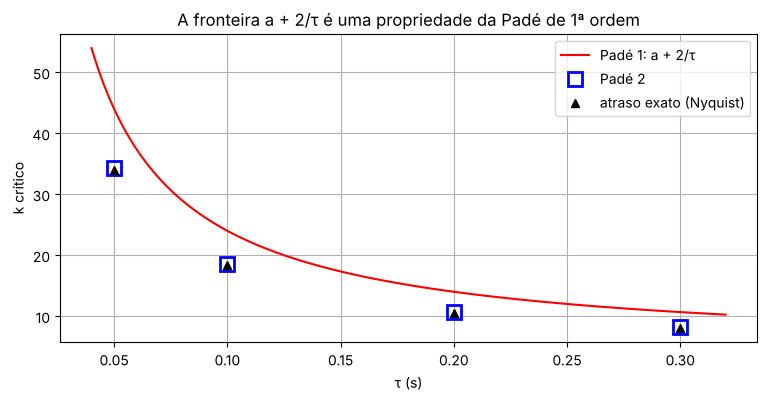

In [13]:
a = 4
taus = [0.05, 0.1, 0.2, 0.3]
def kcrit(n, tau):
    """Ganho crítico: primeiro k (bisseção em polos) com Padé de ordem n."""
    P = ct.tf(*ct.pade(tau, n))
    f = lambda k: max(np.roots(np.polyadd(np.polymul([1, a], P.den[0][0]), k*P.num[0][0])).real)
    return optimize.brentq(f, 1, 200)
def kverdadeiro(tau):
    w = optimize.brentq(lambda w: w*tau + np.arctan(w/a) - np.pi, 1e-3, 1e3)
    return np.hypot(w, a), w
# fronteira por Routh (Padé 2): c2·c1 = c3·c0  → quadrática em k
def krouth2(tau):
    c3 = tau**2/12
    q2 = -c3*tau/2
    q1 = c3*(1 + a*tau/2) - (tau/2)*(tau/2 + c3*a) - c3
    q0 = (tau/2 + c3*a)*(1 + a*tau/2) - c3*a
    return np.roots([q2, q1, q0])
print(f'{"τ":>5} {"a+2/τ":>8} {"Padé 1":>8} {"Padé 2":>8} {"Routh 2 (quadr.)":>18} {"atraso exato":>13} | erro Padé1 | erro Padé2')
res = []
for tau in taus:
    k1, k2, (ke, w) = kcrit(1, tau), kcrit(2, tau), kverdadeiro(tau)
    rr = [r.real for r in krouth2(tau) if abs(r.imag) < 1e-9 and 1 < r.real < a + 2/tau]
    res.append((tau, a+2/tau, k1, k2, ke))
    print(f'{tau:5.2f} {a+2/tau:8.2f} {k1:8.2f} {k2:8.2f} {rr[0]:18.3f} {ke:13.2f} | {100*(k1/ke-1):+6.1f}%   | {100*(k2/ke-1):+6.1f}%')
res = np.array(res)
tt = np.linspace(0.04, 0.32, 200)
plt.plot(tt, a + 2/tt, 'r-', label='Padé 1: a + 2/τ')
plt.plot(res[:, 0], res[:, 3], 'bs', mfc='none', ms=10, mew=2, label='Padé 2')
plt.plot(res[:, 0], res[:, 4], 'k^', label='atraso exato (Nyquist)')
plt.xlabel('τ (s)'); plt.ylabel('k crítico'); plt.legend(); plt.title('A fronteira a + 2/τ é uma propriedade da Padé de 1ª ordem');

**Confirmado.**

| $\tau$ (s) | $a+2/\tau$ (Padé 1) | Padé 2 | atraso exato | erro Padé 1 | erro Padé 2 |
|---|---|---|---|---|---|
| $0{,}05$ | $44{,}00$ | $34{,}32$ | $34{,}01$ | $+29\%$ | $+0{,}9\%$ |
| $0{,}10$ | $24{,}00$ | $18{,}54$ | $18{,}35$ | $+31\%$ | $+1{,}0\%$ |
| $0{,}20$ | $14{,}00$ | $10{,}71$ | $10{,}58$ | $+32\%$ | $+1{,}2\%$ |
| $0{,}30$ | $10{,}67$ | $8{,}15$ | $8{,}04$ | $+33\%$ | $+1{,}4\%$ |

**A fronteira $k=a+2/\tau$ NÃO se mantém** com a Padé de 2ª ordem: ela cai para $34{,}3;\ 18{,}5;\ 10{,}7;\ 8{,}1$, a menor raiz da quadrática de
Routh (as colunas "Padé 2" e "Routh 2" da tabela impressa coincidem: a busca por polos e a quadrática dão o mesmo ganho). E o resultado mais
importante: a Padé de 2ª ordem fica a $\approx1\%$ do **atraso verdadeiro**, enquanto a de 1ª ordem **superestima em ~30%** o ganho
seguro. A razão: $e^{-s\tau}$ tem módulo 1 e fase $-\omega\tau$ **ilimitada**; a Padé de 1ª ordem tem fase limitada em
$-180°$ (e só reproduz $-\omega\tau$ para $\omega\tau\ll1$), logo "enxerga" um atraso menor em altas frequências — justamente onde a
instabilidade acontece ($\omega\approx18$ rad/s para $\tau=0{,}1$ s; $\omega\tau\approx1{,}8$). **Conclusão prática:** a regra
$k<a+2/\tau$ é ótima para *entender o fenômeno* (atraso maior ⇒ ganho crítico menor) e para o projeto de baixa frequência (Partes 3 e 4:
$\omega_d\tau\approx0{,}4$), mas para **dimensionar uma margem de ganho** use Padé de ordem ≥ 2 ou o atraso exato (Nyquist/Bode, Módulo 03).

## Resposta 3 — Projeto com atraso dividido ($0{,}05$ s na malha direta + $0{,}05$ s na realimentação)

**Parte (a): qual $t_r$ mediríamos com o avanço da Parte 4?** O avanço $14{,}26\frac{s+4}{s+8{,}8}$ foi projetado para $t_r=0{,}5$ s com o atraso
todo na realimentação. Pela relação da Parte 3, só o atraso **da malha direta** desloca o tempo de subida medido: $t_r\approx0{,}5+0{,}05=0{,}55$ s,
com $M_p\approx14{,}2\%$ (a posição não afeta o overshoot).

**Parte (b): reprojeto.** Para medir $0{,}5$ s com $0{,}05$ s de deslocamento, projetamos para $t_r^{proj}=0{,}45$ s; para o overshoot,
compensamos **todo** o atraso ($0{,}1$ s). Receita:

1. $M_p=15\%\Rightarrow\zeta=0{,}517$; $\omega_d=\dfrac{\pi-\arccos\zeta}{0{,}45}=4{,}70$; $\omega_n=\omega_d/\sqrt{1-\zeta^2}=5{,}49$; $\sigma=\zeta\omega_n=2{,}84$ ⇒ $\square_d=-2{,}84+4{,}70j$;
2. avanço **sem** atraso: $\angle G(\square_d)=-197{,}2°\Rightarrow17{,}2°$;
3. fase do atraso **inteiro**: $-\tau\omega_d=-0{,}1\times4{,}70\ \text{rad}=-26{,}9°$;
4. avanço total $17{,}2°+26{,}9°=44{,}1°$ — **acima dos $40°$** da regra prática (ainda funciona, mas com pouca margem; veja a ressalva abaixo);
5. cancelando o polo $-4$: fase do zero $76{,}1°$ ⇒ fase do polo $=76{,}1°-44{,}1°=32{,}0°$ ⇒ $b=2{,}84+\dfrac{4{,}70}{\tan32{,}0°}=10{,}37$;
6. ganho: $k=\dfrac{|\square_d|\,|\square_d+b|}{2\,|e^{-0{,}1\square_d}|}$ (módulo do atraso inteiro) $=18{,}3$ (com o módulo da Padé: $18{,}6$).

(a) avanço da Parte 4, atraso dividido: Mp = 14.23%, tr = 0.552 s  (previsto: 0,5 + 0,05 = 0,55 s)
ζ = 0.5169
tr_proj = 0.5: □d = -2.553+4.228j; avanço s/ atraso = 12.24°, fase do atraso = 24.23°, total = 36.46°, fase do polo = 34.65°, b = 8.671, k = 14.23
tr_proj = 0.45: □d = -2.837+4.698j; avanço s/ atraso = 17.22°, fase do atraso = 26.92°, total = 44.14°, fase do polo = 31.96°, b = 10.368, k = 18.34

C_novo(s) = 18.34(s+4)/(s+10.37)
  dividido (Padé 1)           : Mp = 14.94%  tr = 0.494 s  ts = 1.01 s


  dividido (≈ exato, Padé 6)  : Mp = 15.06%  tr = 0.494 s  ts = 1.01 s
  realimentação (Padé 1)      : Mp = 14.71%  tr = 0.445 s  ts = 0.96 s


  malha direta (Padé 1)       : Mp = 14.51%  tr = 0.546 s  ts = 1.06 s


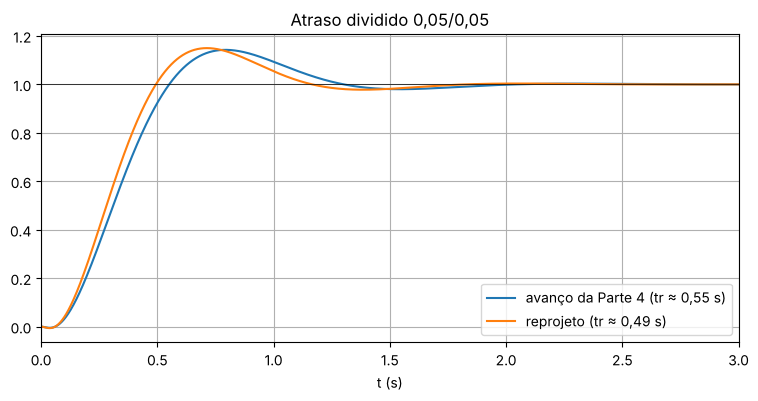

In [14]:
G = ct.tf([2], [1, 4, 0])
P  = ct.tf(*ct.pade(0.1, 1)); P2 = ct.tf(*ct.pade(0.05, 1))
P6 = ct.tf(*ct.pade(0.1, 6)); P6b = ct.tf(*ct.pade(0.05, 6))
t = np.linspace(0, 6, 12000)

# (a) o avanço da Parte 4 com o atraso dividido
C4 = 14.26*ct.tf([1, 4], [1, 8.8])
m = medir(ct.feedback(C4*P2*G, P2), t)
print(f'(a) avanço da Parte 4, atraso dividido: Mp = {m["Mp"]:.2f}%, tr = {m["tr"]:.3f} s  (previsto: 0,5 + 0,05 = 0,55 s)')

# (b) reprojeto
zeta = -np.log(0.15)/np.sqrt(np.pi**2 + np.log(0.15)**2)
def projetar(tr_proj, tau_total=0.1):
    wd = (np.pi - np.arccos(zeta))/tr_proj; wn = wd/np.sqrt(1 - zeta**2)
    sd = -zeta*wn + 1j*wd
    angG = np.degrees(np.angle(2/(sd*(sd+4)))) - 360
    lead = -angG - 180; fase_at = np.degrees(tau_total*wd); total = lead + fase_at
    zf = np.degrees(np.angle(sd + 4)); pf = zf - total
    b = -sd.real + sd.imag/np.tan(np.radians(pf))
    k = abs(sd)*abs(sd + b)/(2*np.exp(-tau_total*sd.real))
    return sd, lead, fase_at, total, zf, pf, b, k
print(f'ζ = {zeta:.4f}')
for trp in (0.5, 0.45):
    sd, lead, fa, tot, zf, pf, b, k = projetar(trp)
    print(f'tr_proj = {trp}: □d = {sd:.3f}; avanço s/ atraso = {lead:.2f}°, fase do atraso = {fa:.2f}°, total = {tot:.2f}°, '
          f'fase do polo = {pf:.2f}°, b = {b:.3f}, k = {k:.2f}')
sd, lead, fa, tot, zf, pf, b, k = projetar(0.45)
Cnew = k*ct.tf([1, 4], [1, b])
print(f'\nC_novo(s) = {k:.2f}(s+4)/(s+{b:.2f})')
for nome, T in [('dividido (Padé 1)', ct.feedback(Cnew*P2*G, P2)), ('dividido (≈ exato, Padé 6)', ct.feedback(Cnew*P6b*G, P6b)),
                ('realimentação (Padé 1)', ct.feedback(Cnew*G, P)), ('malha direta (Padé 1)', ct.feedback(Cnew*P*G, 1))]:
    m = medir(T, t); print(f'  {nome:28s}: Mp = {m["Mp"]:.2f}%  tr = {m["tr"]:.3f} s  ts = {m["ts"]:.2f} s')
plt.plot(*step(ct.feedback(C4*P2*G, P2), t), label='avanço da Parte 4 (tr ≈ 0,55 s)')
plt.plot(*step(ct.feedback(Cnew*P2*G, P2), t), label='reprojeto (tr ≈ 0,49 s)')
plt.axhline(1, color='k', lw=0.5); plt.xlim(0, 3); plt.legend(); plt.xlabel('t (s)'); plt.title('Atraso dividido 0,05/0,05');

**Confirmado.**

- **(a)** Com o atraso dividido, o avanço da Parte 4 dá $M_p=14{,}2\%$ e $t_r=0{,}552$ s: exatamente os $0{,}5$ s + $0{,}05$ s (só a metade do
  atraso, a da malha direta, entra no tempo).
- **(b)** O reprojeto ($\square_d=-2{,}84+4{,}70j$, $b=10{,}37$, $k=18{,}3$) produz, com o atraso dividido, $M_p\approx14{,}9\%$ (alvo $15\%$; com o atraso quase exato, $15{,}1\%$) e
  $t_r\approx0{,}49$ s (alvo $0{,}5$ s). Na realimentação mediria $t_r=0{,}445$ s e na malha direta $0{,}546$ s (o dividido fica no meio, $0{,}494$ s).
  O overshoot é essencialmente o mesmo nas três posições ($14{,}5$–$14{,}9\%$).
- **Ressalva do projeto:** o avanço total de $44{,}1°$ ultrapassa a regra dos $40°$. Funciona aqui porque o polo do avanço ainda fica
  longe ($b=10{,}4$), mas o ganho sobe de $14{,}3$ para $18{,}3$ (mais esforço de controle) e o 4º polo de MF sai do cancelamento
  do $-4$ com cada vez menos folga. É o custo de pedir $t_r$ menor *e* compensar o atraso — se a margem de $40°$ fosse crítica, o caminho seria
  relaxar $t_r$ (ou $M_p$) ou usar avanço duplo.